In [2]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# STEP 1: DATA CLEANING

file_path = "cleaned_equal_weighted_daily.csv"

# Load the data
df = pd.read_csv(file_path, skiprows=0, low_memory=False)

# Replace missing values with NaN
df = df.replace([-99.99, -999], pd.NA)

# Rename first column
df.rename(columns={df.columns[0]: "Date"}, inplace=True)

# Convert Date from YYYYMMDD format to proper datetime
df["Date"] = pd.to_datetime(df["Date"].astype(str), format="%Y%m%d", errors="coerce")

# Convert other columns to numeric
for col in df.columns[1:]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    
# Drop rows with missing dates or all missing data
df = df.dropna(subset=['Date'])
df = df.dropna(how='all', subset=df.columns[1:])

print(f"Data shape: {df.shape}")
print(f"Date range: {df['Date'].min()} to {df['Date'].max()}")
print(df.head())

Data shape: (0, 101)
Date range: NaT to NaT
Empty DataFrame
Columns: [Date, Port_1, Port_2, Port_3, Port_4, Port_5, Port_6, Port_7, Port_8, Port_9, Port_10, Port_11, Port_12, Port_13, Port_14, Port_15, Port_16, Port_17, Port_18, Port_19, Port_20, Port_21, Port_22, Port_23, Port_24, Port_25, Port_26, Port_27, Port_28, Port_29, Port_30, Port_31, Port_32, Port_33, Port_34, Port_35, Port_36, Port_37, Port_38, Port_39, Port_40, Port_41, Port_42, Port_43, Port_44, Port_45, Port_46, Port_47, Port_48, Port_49, Port_50, Port_51, Port_52, Port_53, Port_54, Port_55, Port_56, Port_57, Port_58, Port_59, Port_60, Port_61, Port_62, Port_63, Port_64, Port_65, Port_66, Port_67, Port_68, Port_69, Port_70, Port_71, Port_72, Port_73, Port_74, Port_75, Port_76, Port_77, Port_78, Port_79, Port_80, Port_81, Port_82, Port_83, Port_84, Port_85, Port_86, Port_87, Port_88, Port_89, Port_90, Port_91, Port_92, Port_93, Port_94, Port_95, Port_96, Port_97, Port_98, Port_99, ...]
Index: []

[0 rows x 101 columns]


In [8]:
# STEP 2: PREPARE FOR ROLLING WINDOW

# Convert returns to decimals and set date index
returns_df = df.set_index('Date') / 100.0
print(f"Returns data shape: {returns_df.shape}")
print(f"Number of assets: {returns_df.shape[1]}")

# Find key dates
dates = returns_df.index

# Find 2025-01-02 (start of validation 2)
val2_start = pd.to_datetime('2025-01-02')
val2_start_idx = None
for i, date in enumerate(dates):
    if date >= val2_start:
        val2_start_idx = i
        break

print(f"{len(dates)=}")

if val2_start_idx is None:
    print("Warning: 2025-01-02 not found, using last 200 days")
    val2_start_idx = len(dates) - 200

# Training window: 126 days before validation 2
window_size = 126
train_start_idx = max(0, val2_start_idx - window_size)

print(f"Validation 2 starts at index: {val2_start_idx} ({dates[val2_start_idx]})")
print(f"Training window: {window_size} days")

Returns data shape: (0, 100)
Number of assets: 100
len(dates)=0


IndexError: index -200 is out of bounds for axis 0 with size 0

In [4]:
# STEP 3: PORTFOLIO CONSTRUCTION SETUP

# Get number of assets
n_assets = returns_df.shape[1]

# Create equally weighted portfolio
w_EW = np.ones(n_assets) / n_assets

# Create N matrix for transformation: w = w_EW - N*beta
I_p_minus_1 = np.eye(n_assets - 1)
ones_p_minus_1 = np.ones((n_assets - 1, 1))
N = np.vstack([I_p_minus_1, -ones_p_minus_1.T])

print(f"N matrix shape: {N.shape}")
print(f"EW portfolio sum: {w_EW.sum():.6f}")

N matrix shape: (100, 99)
EW portfolio sum: 1.000000


In [5]:
# STEP 4: ROLLING WINDOW WITH MANUAL CROSS-VALIDATION

# Initialize storage for results
portfolio_returns = {
    'EW': [],
    'MinVar': [],
    'LASSO': [],
    'Ridge': []
}

# Alpha candidates for regularization
alphas = np.logspace(-8, 8, 21)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Rolling window loop
print("Starting rolling window...")
for day_idx in range(val2_start_idx, min(val2_start_idx + 100, len(dates))):  # Limit for demo
    if day_idx % 20 == 0:
        print(f"Processing day {day_idx - val2_start_idx + 1}")
    
    # Get training window (126 days before current day)
    train_start = max(0, day_idx - window_size)
    train_end = day_idx
    
    if train_end - train_start < 50:  # Skip if not enough data
        continue
        
    # Training data
    train_returns = returns_df.iloc[train_start:train_end].values
    
    # Create linear regression data
    y = train_returns @ w_EW  # Target
    X = train_returns @ N     # Features
    
    # Skip if not enough variation
    if X.shape[0] < X.shape[1]:
        continue
    
    # 1. EW Portfolio (baseline)
    w_portfolio_EW = w_EW
    
    # 2. MinVar Portfolio (OLS)
    ols = LinearRegression(fit_intercept=True)
    ols.fit(X, y)
    beta_ols = ols.coef_
    w_portfolio_MinVar = w_EW - (N @ beta_ols.reshape(-1, 1)).flatten()
    
    # 3. LASSO with manual CV
    lasso_cv_scores = []
    for alpha in alphas:
        fold_scores = []
        for train_idx, val_idx in kfold.split(X):
            X_train, X_val = X[train_idx], X[val_idx]
            y_train, y_val = y[train_idx], y[val_idx]
            
            lasso = Lasso(alpha=alpha, max_iter=1000)
            lasso.fit(X_train, y_train)
            
            y_pred = lasso.predict(X_val)
            mse = np.mean((y_val - y_pred)**2)
            fold_scores.append(mse)
        
        lasso_cv_scores.append(np.mean(fold_scores))
    
    best_lasso_alpha = alphas[np.argmin(lasso_cv_scores)]
    final_lasso = Lasso(alpha=best_lasso_alpha, max_iter=1000)
    final_lasso.fit(X, y)
    beta_lasso = final_lasso.coef_
    w_portfolio_LASSO = w_EW - (N @ beta_lasso.reshape(-1, 1)).flatten()
    
    # 4. Ridge with manual CV
    ridge_cv_scores = []
    for alpha in alphas:
        fold_scores = []
        for train_idx, val_idx in kfold.split(X):
            X_train, X_val = X[train_idx], X[val_idx]
            y_train, y_val = y[train_idx], y[val_idx]
            
            ridge = Ridge(alpha=alpha, max_iter=1000)
            ridge.fit(X_train, y_train)
            
            y_pred = ridge.predict(X_val)
            mse = np.mean((y_val - y_pred)**2)
            fold_scores.append(mse)
        
        ridge_cv_scores.append(np.mean(fold_scores))
    
    best_ridge_alpha = alphas[np.argmin(ridge_cv_scores)]
    final_ridge = Ridge(alpha=best_ridge_alpha, max_iter=1000)
    final_ridge.fit(X, y)
    beta_ridge = final_ridge.coef_
    w_portfolio_Ridge = w_EW - (N @ beta_ridge.reshape(-1, 1)).flatten()
    
    # Calculate returns for current day
    if day_idx < len(returns_df):
        day_returns = returns_df.iloc[day_idx].values
        
        ret_EW = np.dot(w_portfolio_EW, day_returns)
        ret_MinVar = np.dot(w_portfolio_MinVar, day_returns)
        ret_LASSO = np.dot(w_portfolio_LASSO, day_returns)
        ret_Ridge = np.dot(w_portfolio_Ridge, day_returns)
        
        portfolio_returns['EW'].append(ret_EW)
        portfolio_returns['MinVar'].append(ret_MinVar)
        portfolio_returns['LASSO'].append(ret_LASSO)
        portfolio_returns['Ridge'].append(ret_Ridge)

print(f"Rolling window complete. Generated {len(portfolio_returns['EW'])} portfolio returns.")


Starting rolling window...
Processing day 20
Processing day 40
Processing day 60
Processing day 80
Processing day 100
Rolling window complete. Generated 100 portfolio returns.


In [6]:
# STEP 5: PERFORMANCE EVALUATION
# Calculate Sharpe ratios
results = {}
for method in portfolio_returns.keys():
    returns = np.array(portfolio_returns[method])
    if len(returns) > 0:
        mean_ret = np.mean(returns)
        std_ret = np.std(returns)
        sharpe = mean_ret / std_ret if std_ret > 0 else 0
        
        results[method] = {
            'mean_return': mean_ret,
            'std_return': std_ret,
            'sharpe_ratio': sharpe,
            'cumulative_return': (1 + returns).prod() - 1
        }

print("\n" + "="*50)
print("PERFORMANCE RESULTS")
print("="*50)
for method, metrics in results.items():
    print(f"{method}:")
    print(f"  Mean Return: {metrics['mean_return']*100:.4f}%")
    print(f"  Std Deviation: {metrics['std_return']*100:.4f}%") 
    print(f"  Sharpe Ratio: {metrics['sharpe_ratio']:.4f}")
    print(f"  Cumulative Return: {metrics['cumulative_return']*100:.2f}%")
    print()


PERFORMANCE RESULTS
EW:
  Mean Return: -0.0209%
  Std Deviation: 1.7512%
  Sharpe Ratio: -0.0119
  Cumulative Return: -3.55%

MinVar:
  Mean Return: -0.0739%
  Std Deviation: 1.4947%
  Sharpe Ratio: -0.0495
  Cumulative Return: -8.17%

LASSO:
  Mean Return: 0.0111%
  Std Deviation: 1.0693%
  Sharpe Ratio: 0.0104
  Cumulative Return: 0.54%

Ridge:
  Mean Return: -0.0290%
  Std Deviation: 1.0555%
  Sharpe Ratio: -0.0275
  Cumulative Return: -3.40%



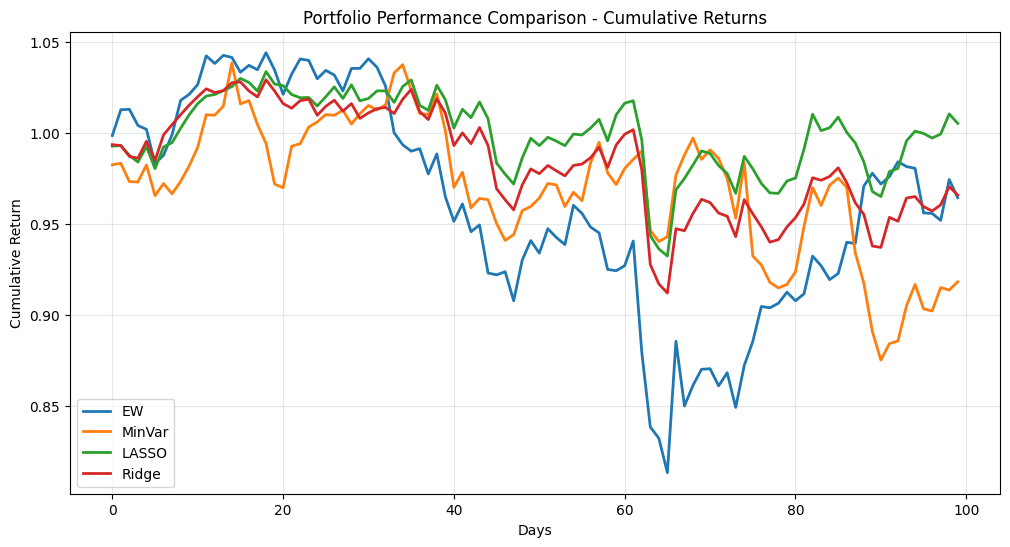

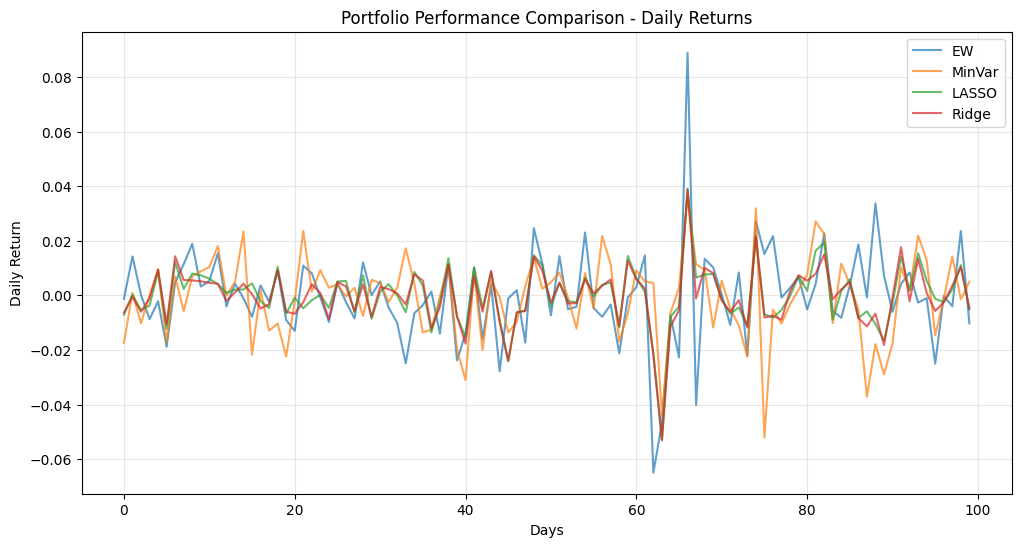

Analysis complete!


In [7]:
# STEP 6: VISUALIZATION

if len(portfolio_returns['EW']) > 0:
    # Plot cumulative returns
    plt.figure(figsize=(12, 6))
    
    for method in portfolio_returns.keys():
        returns = np.array(portfolio_returns[method])
        cum_returns = np.cumprod(1 + returns)
        plt.plot(cum_returns, label=method, linewidth=2)
    
    plt.title('Portfolio Performance Comparison - Cumulative Returns')
    plt.xlabel('Days')
    plt.ylabel('Cumulative Return')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    
    # Plot daily returns
    plt.figure(figsize=(12, 6))
    
    for method in portfolio_returns.keys():
        returns = np.array(portfolio_returns[method])
        plt.plot(returns, label=method, alpha=0.7)
    
    plt.title('Portfolio Performance Comparison - Daily Returns')
    plt.xlabel('Days')
    plt.ylabel('Daily Return')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

print("Analysis complete!")